In [64]:
words= open("data/shakespeare_100k.txt", "r").read().splitlines()

In [65]:
words[:10]

['THE',
 'SONNETS',
 'ALL',
 'IS',
 'WELL',
 'THAT',
 'ENDS',
 'WELL',
 'THE',
 'TRAGEDY']

In [66]:
len(words[15])

3

In [67]:

store = 0

for w in range(len(words)):
    if len(words[w]) > len(words[store]):
        store = w

print(store)
print(words[store])

36396
Portotartarossa


# Bigram model :

 In bigram model we are going to predict the next character based on the just the previous char
 
 In order to learn which charaters are likely to follow which chars statistically the simplest way is to use count of there co-occurrence

In [68]:

#this whole code creates char & prevChar pairing and count of their co-occurrence
b={}
for w in words:
    chs=["<S>"] + list(w) + ["<E>"] # doing this stores a very usefull imformation about the characters which begin a word and end a word
    for ch1, ch2 in zip(chs,chs[1:]):
        bigram=(ch1,ch2)
        b[bigram]=b.get(bigram,0)+1

In [69]:
sorted(b.items(),key=lambda kv: -kv[1]) # sorted bigram count in descending order

[(('e', '<E>'), 18270),
 (('<S>', 't'), 11637),
 (('t', 'h'), 10797),
 (('t', '<E>'), 10745),
 (('s', '<E>'), 10557),
 (('h', 'e'), 8605),
 (('d', '<E>'), 8582),
 (('r', '<E>'), 7216),
 (('<S>', 's'), 7048),
 (('<S>', 'a'), 6631),
 (('y', '<E>'), 6480),
 (('n', '<E>'), 6188),
 (('o', 'u'), 6044),
 (('e', 'r'), 5841),
 (('<S>', 'h'), 5638),
 (('<S>', 'm'), 5458),
 (('i', 'n'), 5419),
 (('<S>', 'w'), 5262),
 (('a', 'n'), 4903),
 (('r', 'e'), 4779),
 (('h', 'a'), 4535),
 (('o', '<E>'), 4515),
 (('n', 'd'), 4411),
 (('a', 't'), 3892),
 (('<S>', 'b'), 3876),
 (('<S>', 'i'), 3794),
 (('o', 'r'), 3732),
 (('<S>', 'o'), 3729),
 (('e', 's'), 3540),
 (('i', 's'), 3537),
 (('e', 'n'), 3493),
 (('a', 'r'), 3391),
 (('h', 'i'), 3390),
 (('<S>', 'I'), 3344),
 (('l', '<E>'), 3331),
 (('h', '<E>'), 3315),
 (('v', 'e'), 3269),
 (('<S>', 'f'), 3217),
 (('s', 't'), 3168),
 (('l', 'l'), 3116),
 (('o', 'n'), 3022),
 (('m', 'e'), 2935),
 (('<S>', 'd'), 2919),
 (('e', 'a'), 2896),
 (('i', 't'), 2867),
 (('<S

In [70]:
# pytorch and tensors
import torch

a=torch.zeros((3,5),dtype=torch.int32)
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [71]:
a[1,3]=1
a

tensor([[0, 0, 0, 0, 0],
        [0, 0, 0, 1, 0],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

In [83]:
# storing this dictionary as co-occurrence matrix using tensors in pytorch

N = torch.zeros((52,52),dtype=torch.int32) 
# we have 53 unique chars in our dataset including capital small letters and special characters that we introduced

In [84]:
lookup=sorted(list(set(''.join(words)))) #lookup table for string to integer mapping of the chars of our dtaset
stoi={s:i+1 for i,s in enumerate(lookup)}
stoi['.']=0 #instead of two chars <S> <E> we will have '.'
itos={i:s for s,i in stoi.items()}

In [85]:
# initialise N matrix

for w in words:
    chs=["."] + list(w) + ["."] 
    for ch1, ch2 in zip(chs,chs[1:]):
        ix1=stoi[ch1]
        ix2=stoi[ch2]
        N[ix1,ix2]+=1

In [86]:
#our co-occurrence matrix
N

tensor([[   0, 2478,  883,  ...,    0, 2450,    2],
        [ 849,    0,   26,  ...,    0,   59,    0],
        [   0,  120,    0,  ...,    0,   93,    0],
        ...,
        [  48,    0,    0,  ...,    0,    0,    0],
        [6480,    0,    0,  ...,    0,    0,    0],
        [  12,    0,    0,  ...,    0,    1,    4]], dtype=torch.int32)

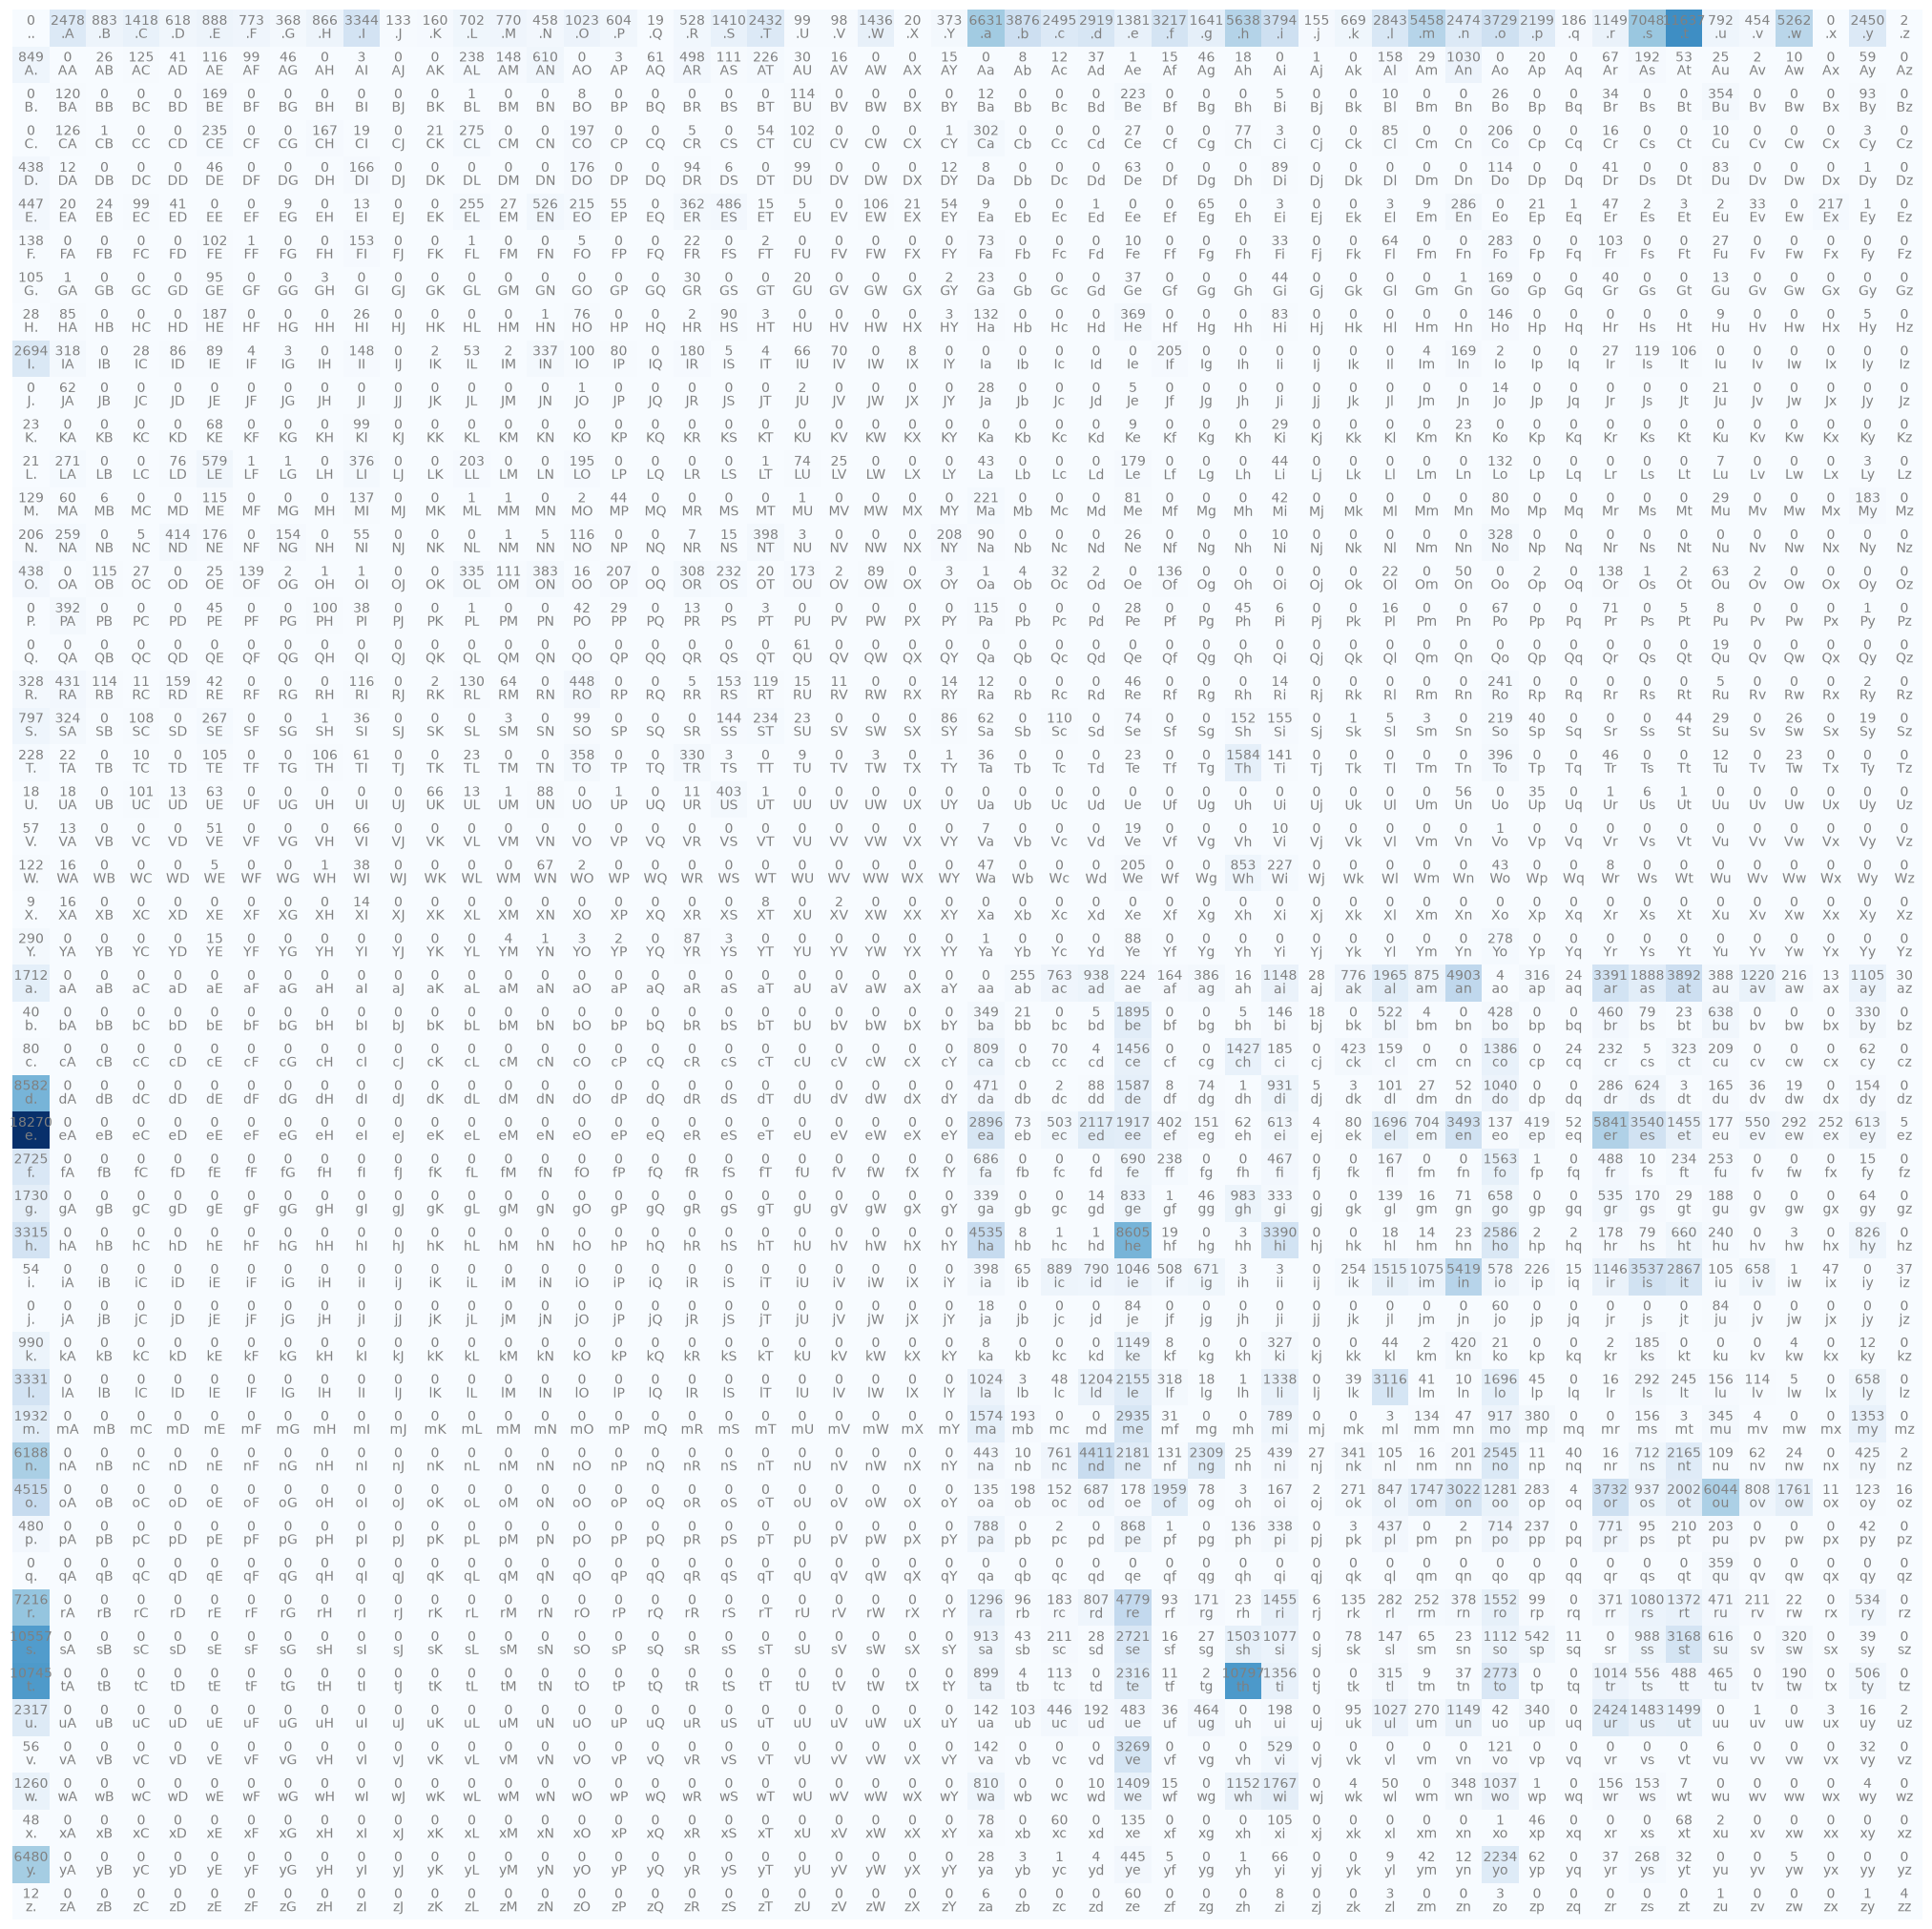

In [87]:
#visualisation of N using matplotlib

import matplotlib.pyplot as plt
%matplotlib inline

plt.figure(figsize=(26,26))
plt.imshow(N, cmap='Blues')

for i in range(52):
    for j in range(52):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="top", color="gray")
        plt.text(j, i, N[i,j].item(), ha='center', va='bottom', color="gray")

plt.axis('off');


In [88]:
N[0]

tensor([    0,  2478,   883,  1418,   618,   888,   773,   368,   866,  3344,
          133,   160,   702,   770,   458,  1023,   604,    19,   528,  1410,
         2432,    99,    98,  1436,    20,   373,  6631,  3876,  2495,  2919,
         1381,  3217,  1641,  5638,  3794,   155,   669,  2843,  5458,  2474,
         3729,  2199,   186,  1149,  7048, 11637,   792,   454,  5262,     0,
         2450,     2], dtype=torch.int32)

In [ ]:
p= N[0].float()
p= p/p.sum() # making the real numbers as probalities 
p

tensor([0.0000e+00, 2.4780e-02, 8.8300e-03, 1.4180e-02, 6.1800e-03, 8.8800e-03,
        7.7300e-03, 3.6800e-03, 8.6600e-03, 3.3440e-02, 1.3300e-03, 1.6000e-03,
        7.0200e-03, 7.7000e-03, 4.5800e-03, 1.0230e-02, 6.0400e-03, 1.9000e-04,
        5.2800e-03, 1.4100e-02, 2.4320e-02, 9.9000e-04, 9.8000e-04, 1.4360e-02,
        2.0000e-04, 3.7300e-03, 6.6310e-02, 3.8760e-02, 2.4950e-02, 2.9190e-02,
        1.3810e-02, 3.2170e-02, 1.6410e-02, 5.6380e-02, 3.7940e-02, 1.5500e-03,
        6.6900e-03, 2.8430e-02, 5.4580e-02, 2.4740e-02, 3.7290e-02, 2.1990e-02,
        1.8600e-03, 1.1490e-02, 7.0480e-02, 1.1637e-01, 7.9200e-03, 4.5400e-03,
        5.2620e-02, 0.0000e+00, 2.4500e-02, 2.0000e-05])

In [90]:
p.sum()

tensor(1.)